URL = https://github.com/hongleir/SpaceFlow/tree/master

In [1]:
# !pip install SpaceFlow
# !pip install scanpy anndata pandas numpy scipy matplotlib

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from SpaceFlow import SpaceFlow

/home/user/Gagan_env/genomicsProject/.genomicsProjectENV/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/user/Gagan_env/genomicsProject/.genomicsProjectENV/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
BASE = Path("../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results")
# DATA_DIR = "../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1"
OUT = BASE / "SpaceFlow"
OUT.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(BASE / "S1R1_prepared.h5ad")

# SpaceFlow should receive the original count matrix here.
adata.X = adata.layers["counts"].copy()

In [4]:
# Build and run the model.
sf = SpaceFlow.SpaceFlow(adata=adata)
sf.preprocessing_data(n_top_genes=min(400, adata.n_vars))

sf.train(
    spatial_regularization_strength=0.1,
    embedding_save_filepath=OUT / "embedding.tsv",
    z_dim=50,
    lr=1e-3,
    epochs=500,
    max_patience=50,
    min_stop=100,
    random_seed=42,
    gpu=0,  # Use CPU if no compatible GPU is available.
)

/home/user/Gagan_env/genomicsProject/.genomicsProjectENV/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


AttributeError: module 'networkx' has no attribute 'to_scipy_sparse_matrix'

In [ ]:
# Spatial domains.
sf.segmentation(
    domain_label_save_filepath=str(OUT / "domains.tsv"),
    n_neighbors=20,
    resolution=1.0,
)

Performing domain segmentation
Segmentation complete, domain labels of cells or spots saved at ../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results/SpaceFlow/domains.tsv !


No segmentation data found, please ensure you have run the segmentation() method.


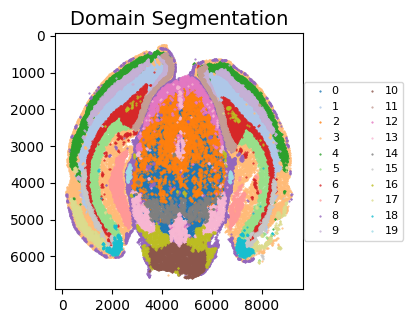

In [ ]:
sf.plot_segmentation(
    segmentation_figure_save_filepath=str(OUT / "spatial_domains.pdf")
)

In [ ]:
# Pseudo-Spatiotemporal Map.
sf.pseudo_Spatiotemporal_Map(
    pSM_values_save_filepath=str(OUT / "pSM_values.tsv"),
    n_neighbors=20,
    resolution=1.0,
)

Performing pseudo-Spatiotemporal Map
pseudo-Spatiotemporal Map(pSM) calculation complete, pSM values of cells or spots saved at ../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results/SpaceFlow/pSM_values.tsv!


In [ ]:
sf.plot_pSM(
    pSM_figure_save_filepath=str(OUT / "pSM.pdf")
)

Plotting complete, pseudo-Spatiotemporal Map figure saved at ../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results/SpaceFlow/pSM.pdf !


In [ ]:
print("SpaceFlow completed. Results:", OUT)

SpaceFlow completed. Results: ../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results/SpaceFlow
